In [53]:
import pandas as pd
import sklearn
import numpy as np
from sklearn.metrics import accuracy_score

In [54]:
df = pd.read_csv("data/heart.csv")

# Exploration

In [55]:
df.describe()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


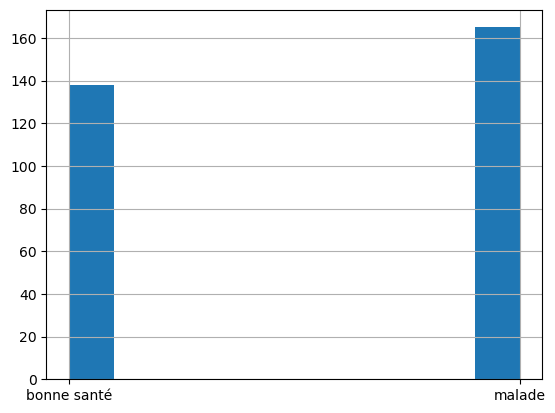

In [56]:
import matplotlib.pyplot as plt
df["output"].hist()
plt.xticks([0, 1], ["bonne santé", "malade"])
plt.show()

# Split

In [57]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df[["age", "sex"]], df["output"], test_size=0.2, random_state=42)

In [58]:
X_test.to_csv("data/X_test.csv", index=False)
y_test.to_csv("data/y_test.csv", index=False)

# Entrainement

In [59]:
X_train

,age,sex
132,42,1
202,58,1
196,46,1
75,55,0
176,60,1
...,...,...
188,50,1
71,51,1
106,69,1
270,46,1


In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

model = LogisticRegression(random_state=0)
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,0
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### Evaluer les performances

In [61]:
preds_test = model.predict(X_test)

In [62]:
accuracy = accuracy_score(y_test, preds_test)
print(f"Pourcentage de bonnes réponse sur le jeu de test : {(accuracy*100):2f} % ")

Pourcentage de bonnes réponse sur le jeu de test : 59.016393 % 


# A vous de jouer : entrainez un nouveau model sur plus de colonnes et tenter d'améliorer les performances

### Faire une prediction sur un example

In [63]:
example = X_test.iloc[0]
example

age    57
sex     1
Name: 179, dtype: int64

In [64]:
answer = model.predict([example])  # input is expected to be batched, so we provide a list of one element
print(f"Prédiction : {answer[0]}") # the output is batched too

Prédiction : 0


c:\Users\benoi\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [65]:
pred_to_string = ["Bonne santé","Malade"]
print(pred_to_string[answer[0]])

Bonne santé


# Sauvegarde du modèle entrainé

In [66]:
import pickle
# save the model to disk
filename = 'datascience_model/first_model.sav'
pickle.dump(model, open(filename, 'wb'))

## Chargement du modèle entrainé

Attention, pickle a besoin que le code et environnement soit le même que celui de l'environnement d'export ! Il ne sauvegarde qu'une version serialisée des objets, mais qui a besoin du code pour les re-créer !

In [67]:
with open(filename,"rb") as f: #rb for binary
    model_loaded = pickle.load(f)

verifions que la prédiction soit la même :

In [68]:
answer = model_loaded.predict([example])
print(pred_to_string[answer[0]])

Bonne santé


c:\Users\benoi\miniconda3\envs\ml\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
